In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("shap",      "shap==0.48.0",          "shap==0.48.0"),
    ("lime",      "lime==0.2.0.1",         "lime==0.2.0.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


Tổng mẫu: 40,651 (benign: 18,051, botnet: 22,600)
Shape sau xử lý: (40651, 77)

=== BÁO CÁO PHÂN LOẠI ===
              precision    recall  f1-score   support

 Bình thường       1.00      1.00      1.00      3611
      Botnet       1.00      1.00      1.00      4520

    accuracy                           1.00      8131
   macro avg       1.00      1.00      1.00      8131
weighted avg       1.00      1.00      1.00      8131

Ma trận nhầm lẫn:
[[3607    4]
 [   6 4514]]

=== 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT ===
            Đặc trưng  Mức độ quan trọng
18       Flow IAT Min           0.138298
16       Flow IAT Std           0.059102
65  Init Bwd Win Byts           0.056798
33     Fwd Header Len           0.056218
1        Tot Fwd Pkts           0.048985
35         Fwd Pkts/s           0.046037
0       Flow Duration           0.040810
23        Fwd IAT Min           0.039211
60   Subflow Fwd Pkts           0.032513
17       Flow IAT Max           0.028752

=== PHÂN TÍCH SHAP ===


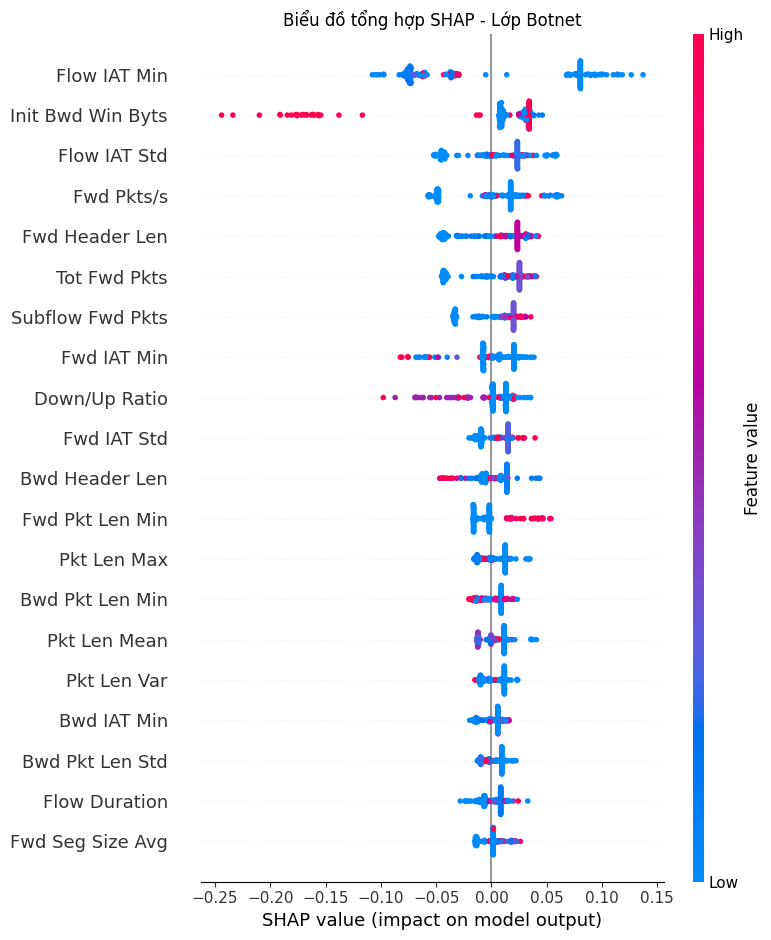


=== BIỂU ĐỒ WATERFALL CHO MẪU THỬ NGHIỆM ĐẦU TIÊN ===


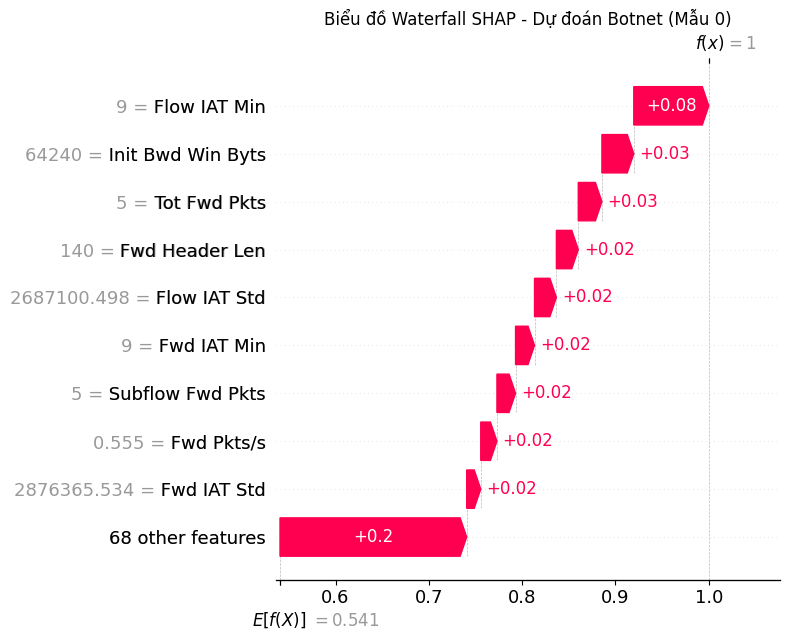


=== PHÂN TÍCH LIME ===


/home/ubuntu/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


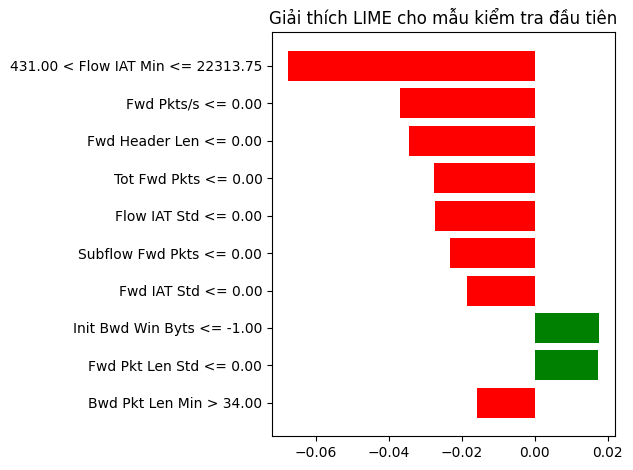


=== 10 ĐẶC TRƯNG ẢNH HƯỞNG NHIỀU NHẤT THEO LIME ===
431.00 < Flow IAT Min <= 22313.75: -0.0676
Fwd Pkts/s <= 0.00: -0.0370
Fwd Header Len <= 0.00: -0.0344
Tot Fwd Pkts <= 0.00: -0.0275
Flow IAT Std <= 0.00: -0.0274
Subflow Fwd Pkts <= 0.00: -0.0232
Fwd IAT Std <= 0.00: -0.0186
Init Bwd Win Byts <= -1.00: 0.0177
Fwd Pkt Len Std <= 0.00: 0.0174
Bwd Pkt Len Min > 34.00: -0.0159


In [2]:
# ============================================================
# XAI GIẢI THÍCH BẤT THƯỜNG BOTNET - FULL CODE (FIX SHAP)
# Dataset: CTU-13
# ============================================================

# 1. IMPORT THƯ VIỆN
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import shap
from lime.lime_tabular import LimeTabularExplainer
from pathlib import Path

# 2. LOAD DỮ LIỆU
root_folder = Path.cwd()
df_benign = pd.read_csv(root_folder / "Dataset" / "CTU13" / "2017-04-28_normal.pcap_Flow.csv")
df_malware = pd.read_csv(root_folder / "Dataset" / "CTU13" / "botnet-capture-20110810-neris.pcap_Flow.csv")

# 3. GÁN NHÃN
df_benign['label_bin'] = 0
df_malware['label_bin'] = 1

# 4. GHÉP DATASET
df = pd.concat([df_benign, df_malware], ignore_index=True)
print(f"Tổng mẫu: {len(df):,} (benign: {(df.label_bin==0).sum():,}, botnet: {(df.label_bin==1).sum():,})")

# 5. LÀM SẠCH DỮ LIỆU
df = df.dropna(axis=1, how='all')  # xóa cột toàn NaN

# Label encoding cho cột object
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))

DROP_COLS = ["Flow ID","Src IP","Src Port","Dst IP","Dst Port","Protocol","Timestamp"]

# Tách features/label
X = df.drop(
    columns=["label_bin"] +
    [c for c in DROP_COLS if c in df.columns]
)
y = df['label_bin']

# Fill NaN
X = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X), columns=X.columns)
print(f"Shape sau xử lý: {X.shape}")

# 6. TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# ============================================================
# 7. HUẤN LUYỆN RANDOM FOREST
# ============================================================
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# ============================================================
# 8. DỰ ĐOÁN VÀ ĐÁNH GIÁ
# ============================================================
y_pred = model.predict(X_test)

print("\n=== BÁO CÁO PHÂN LOẠI ===")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Bình thường", "Botnet"]
    )
)

print("Ma trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred))

# ============================================================
# 9. ĐỘ QUAN TRỌNG CỦA ĐẶC TRƯNG
# ============================================================
importance = pd.DataFrame({
    "Đặc trưng": X.columns,
    "Mức độ quan trọng": model.feature_importances_
})

print("\n=== 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT ===")
print(
    importance
    .sort_values("Mức độ quan trọng", ascending=False)
    .head(10)
)

# ============================================================
# 10. PHÂN TÍCH SHAP
# ============================================================
print("\n=== PHÂN TÍCH SHAP ===")

# Lấy 200 mẫu để trực quan hóa nhanh
X_sample = X_test.sample(n=200, random_state=42)

# Tạo bộ giải thích SHAP
explainer = shap.Explainer(model, X_train)

# Tính giá trị SHAP
shap_values = explainer(X_sample)

# Với bài toán phân loại nhị phân:
# output thứ 1 tương ứng với lớp Botnet
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    show=False
)

plt.title("Biểu đồ tổng hợp SHAP - Lớp Botnet")
plt.tight_layout()
plt.show()

# ============================================================
# WATERFALL PLOT CHO MẪU ĐẦU TIÊN
# ============================================================
print("\n=== BIỂU ĐỒ WATERFALL CHO MẪU THỬ NGHIỆM ĐẦU TIÊN ===")

shap.waterfall_plot(
    shap_values[0, :, 1],
    show=False
)

plt.title("Biểu đồ Waterfall SHAP - Dự đoán Botnet (Mẫu 0)")
plt.tight_layout()
plt.show()

# ============================================================
# 11. PHÂN TÍCH LIME
# ============================================================
print("\n=== PHÂN TÍCH LIME ===")

lime_explainer = LimeTabularExplainer(
    np.array(X_train),
    feature_names=X.columns.tolist(),
    class_names=["Bình thường", "Botnet"],
    mode='classification'
)

# Giải thích mẫu đầu tiên của tập kiểm tra
lime_exp = lime_explainer.explain_instance(
    X_test.iloc[0].values,
    model.predict_proba,
    num_features=10
)

fig = lime_exp.as_pyplot_figure()

plt.title("Giải thích LIME cho mẫu kiểm tra đầu tiên")
plt.tight_layout()
plt.show()

# In chi tiết đóng góp của từng đặc trưng
print("\n=== 10 ĐẶC TRƯNG ẢNH HƯỞNG NHIỀU NHẤT THEO LIME ===")
for feature, weight in lime_exp.as_list():
    print(f"{feature}: {weight:.4f}")
